# Library

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read data

| اسم العمود | الوصف |
| --- | --- |
| **Posted On** | تاريخ نشر إعلان الإيجار. |
| **BHK** | عدد غرف النوم والصالة والمطبخ. |
| **Rent** | قيمة الإيجار الشهري، وهي المتغير المستهدف. |
| **Size** | مساحة الوحدة السكنية بالقدم المربع. |
| **Floor** | الطابق الحالي وإجمالي طوابق المبنى. |
| **Area Type** | طريقة قياس المساحة: Carpet Area أو Super Area أو Built Area. |
| **Area Locality** | المنطقة أو الحي الذي تقع فيه الوحدة. |
| **City** | المدينة التي تقع فيها الوحدة. |
| **Furnishing Status** | حالة تأثيث الوحدة. |
| **Tenant Preferred** | نوع المستأجر المفضل. |
| **Bathroom** | عدد الحمامات. |
| **Point of Contact** | جهة التواصل الخاصة بالإعلان. |

In [76]:
df = pd.read_csv('/Users/pawn/Desktop/NTI/House_Rent_Dataset/House_Rent_Dataset.csv')

In [77]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [79]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

In [80]:
df.shape

(4746, 12)

# Remove column

In [81]:
df['Posted On'] = pd.to_datetime(df['Posted On'], errors='coerce')
df['Posted Year'] = df['Posted On'].dt.year
df['Posted Month'] = df['Posted On'].dt.month
df.drop(['Posted On'], axis=1, inplace=True)

In [82]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

Number of duplicate rows :  3


# Data Cleaning
missing Value

In [83]:
df.isnull().sum().sort_values(ascending=False).head(12)

Size                 8
Area Type            7
Rent                 5
Bathroom             4
BHK                  0
Floor                0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
Posted Year          0
dtype: int64

# Data Visualization

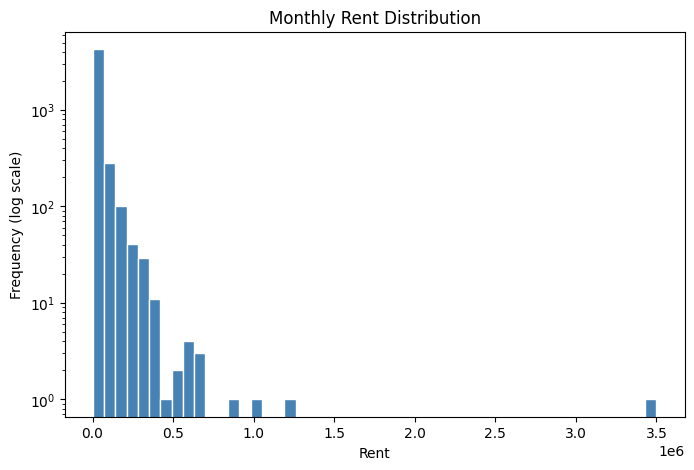

In [84]:
plt.figure(figsize=(8, 5))
plt.hist(df['Rent'].dropna(), bins=50, color='steelblue', edgecolor='white', log=True)
plt.title('Monthly Rent Distribution')
plt.xlabel('Rent')
plt.ylabel('Frequency (log scale)')
plt.show()

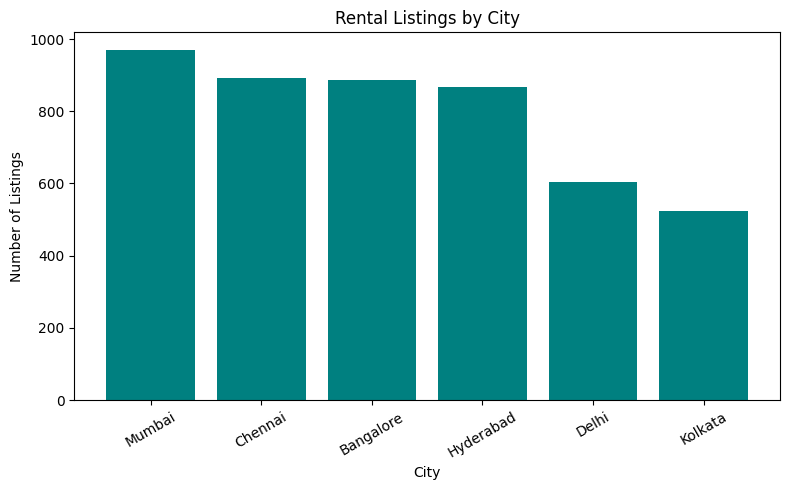

In [85]:
city_counts = df['City'].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(city_counts.index, city_counts.values, color='teal')
plt.title('Rental Listings by City')
plt.xlabel('City')
plt.ylabel('Number of Listings')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

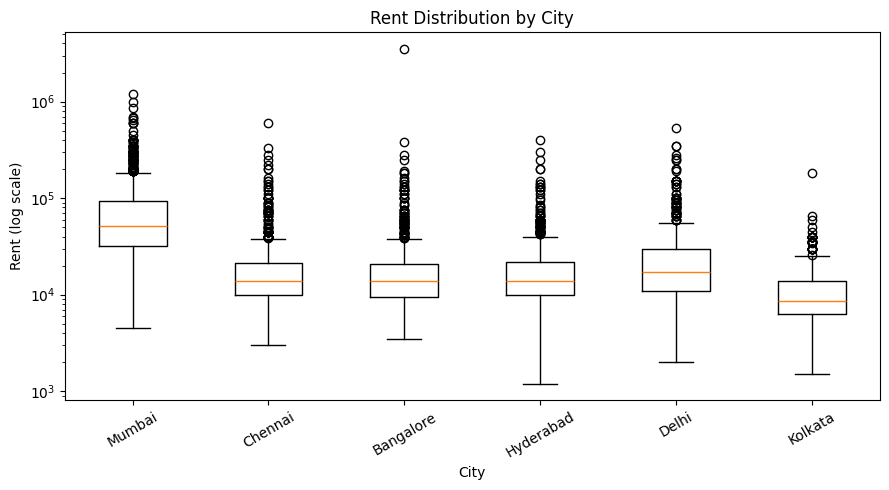

In [86]:
city_order = df['City'].value_counts().index
rent_by_city = [df.loc[df['City'] == city, 'Rent'].dropna() for city in city_order]
plt.figure(figsize=(9, 5))
plt.boxplot(rent_by_city, tick_labels=city_order)
plt.yscale('log')
plt.title('Rent Distribution by City')
plt.xlabel('City')
plt.ylabel('Rent (log scale)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Replace Nan value

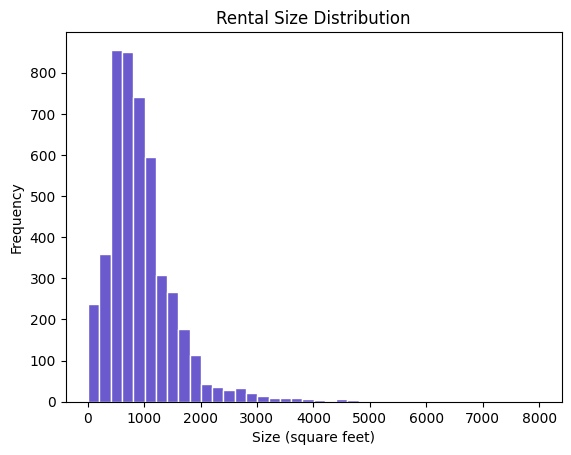

In [87]:
plt.hist(df['Size'].dropna(), bins=40, color='slateblue', edgecolor='white')
plt.title('Rental Size Distribution')
plt.xlabel('Size (square feet)')
plt.ylabel('Frequency')
plt.show()

In [88]:
df['Size'].skew()

np.float64(2.299431974080346)

In [89]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['Size']])
df[['Size']] = imputer.transform(df[['Size']])

# df[['Size']] = imputer.fit_transform(df[['Size']])

In [90]:
df['Size'].isnull().sum()

np.int64(0)

In [91]:
df.isnull().sum().sort_values(ascending=False).head(12)

Area Type            7
Rent                 5
Bathroom             4
BHK                  0
Size                 0
Floor                0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
Posted Year          0
dtype: int64

In [92]:
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df[['Bathroom']] = imputer.fit_transform(df[['Bathroom']])

# Replace categorical NaN values

In [93]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

# Area Type
df[['Area Type']] = imputer.fit_transform(df[['Area Type']])

# Furnishing Status
df[['Furnishing Status']] = imputer.fit_transform(df[['Furnishing Status']])

# Tenant Preferred
df[['Tenant Preferred']] = imputer.fit_transform(df[['Tenant Preferred']])

In [94]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

for col in df.select_dtypes(include=['object']).columns:
    df[[col]] = imputer.fit_transform(df[[col]])

In [95]:
df.isnull().sum().sort_values(ascending=False).head(12)

Rent                 5
BHK                  0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
Posted Year          0
dtype: int64

In [96]:
df.dropna(subset=['Rent'], inplace=True)
df.reset_index(drop=True, inplace=True)

# Remove Duplicated

In [97]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

Number of duplicate rows :  0


# Data Encoding

In [98]:
df.select_dtypes(include=['object']).columns

Index(['Floor', 'Area Type', 'Area Locality', 'City', 'Furnishing Status',
       'Tenant Preferred', 'Point of Contact'],
      dtype='object')

In [99]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of categories in {col}: ', df[col].nunique())
    print(f'values in {col}: ', df[col].unique())

number of categories in Floor:  480
values in Floor:  ['Ground out of 2' '1 out of 3' '1 out of 2' 'Ground out of 1'
 'Ground out of 4' '1 out of 4' '1 out of 1' 'Ground out of 3'
 '2 out of 3' '4 out of 5' '2 out of 2' '2 out of 5' '4 out of 14'
 '3 out of 3' '5 out of 5' '4 out of 4' '7 out of 8' '2 out of 4'
 '3 out of 4' '1 out of 5' '8 out of 5' 'Ground out of 6' '2 out of 1'
 'Upper Basement out of 4' 'Ground out of 5' '3 out of 5' '11 out of 19'
 '5 out of 10' '11 out of 14' 'Lower Basement out of 2' '2 out of 7'
 '4 out of 10' '7 out of 10' '2 out of 13' '6 out of 7' '4 out of 7'
 '14 out of 14' '43 out of 78' '2 out of 8' '13 out of 18' '5 out of 12'
 '18 out of 24' '3 out of 7' '17 out of 31' '11 out of 21' '7 out of 19'
 '14 out of 23' '9 out of 20' 'Upper Basement out of 9' '19 out of 24'
 '3 out of 21' '1 out of 22' '8 out of 8' '6 out of 12' '4 out of 58'
 'Upper Basement out of 16' '60 out of 66' '34 out of 48' '5 out of 8'
 '5 out of 14' '14 out of 40' '5 out of 7' '9 o

## Label encoder

In [100]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['City'] = le.fit_transform(df['City'])
df['Floor'] = le.fit_transform(df['Floor'])
df['Point of Contact'] = le.fit_transform(df['Point of Contact'])

In [101]:
# for col in ['City', 'Floor', 'Point of Contact']:
#     df[col] = le.fit_transform(df[col])

In [102]:
le.inverse_transform(df['Point of Contact'])

array(['Contact Owner', 'Contact Owner', 'Contact Owner', ...,
       'Contact Agent', 'Contact Agent', 'Contact Owner'], dtype=object)

In [103]:
feature_names = le.classes_
print('Feature names before encoding:', feature_names)

Feature names before encoding: ['Contact Agent' 'Contact Builder' 'Contact Owner']


## Ordinal Encoding

In [104]:
from sklearn.preprocessing import OrdinalEncoder

ord_enc = OrdinalEncoder(categories=[['Unfurnished', 'Semi-Furnished', 'Furnished']])
df[['Furnishing Status']] = ord_enc.fit_transform(df[['Furnishing Status']])

## LabelBinarizer

In [105]:
from sklearn.preprocessing import LabelBinarizer

lb = LabelBinarizer()
lb_encoded = lb.fit_transform(df['Tenant Preferred'])
lb_encoded[:5]

array([[0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0]])

In [106]:
from sklearn.preprocessing import label_binarize

tenant_preferred_bin = label_binarize(
    df['Tenant Preferred'],
    classes=lb.classes_
)
tenant_preferred_bin[:5]

array([[0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [0, 1, 0],
       [1, 0, 0]])

## OneHotEncoder

In [107]:
df['Area Type'].unique()

array(['Super Area', 'Carpet Area', 'Built Area'], dtype=object)

In [108]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
ohe_encoded = ohe.fit_transform(df[['Area Type']]).toarray()

In [109]:
print('OneHotEncoder categories:')
print(ohe.categories_[0])

OneHotEncoder categories:
['Built Area' 'Carpet Area' 'Super Area']


In [110]:
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(['Area Type']),
    index=df.index
)

df = pd.concat([df, ohe_df], axis=1)

In [111]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area
0,2,10000.0,1100.000000,455,Super Area,Bandel,4,0.0,Bachelors/Family,2.0,2,2022,5,0.0,0.0,1.0
1,2,20000.0,967.924182,14,Super Area,"Phool Bagan, Kankurgachi",4,1.0,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0
2,2,17000.0,1000.000000,14,Super Area,Salt Lake City Sector 2,4,1.0,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0
3,2,10000.0,967.924182,10,Super Area,Dumdum Park,4,0.0,Bachelors/Family,1.0,2,2022,7,0.0,0.0,1.0
4,2,7500.0,850.000000,10,Carpet Area,South Dum Dum,4,0.0,Bachelors,1.0,2,2022,5,0.0,1.0,0.0


In [112]:
df.drop('Area Type', axis=1, inplace=True)

## TargetEncoder

In [113]:
import category_encoders as ce

In [114]:
target_enc = ce.TargetEncoder(
    cols=['Area Locality'],
    smoothing=5
)

df[['Area Locality_new']] = target_enc.fit_transform(
    df[['Area Locality']], df['Rent']
)

In [115]:
print('Final shape:', df.shape)
df.head()

Final shape: (4738, 16)


,BHK,Rent,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new
0,2,10000.0,1100.000000,455,Bandel,4,0.0,Bachelors/Family,2.0,2,2022,5,0.0,0.0,1.0,34269.612957
1,2,20000.0,967.924182,14,"Phool Bagan, Kankurgachi",4,1.0,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0,34362.702434
2,2,17000.0,1000.000000,14,Salt Lake City Sector 2,4,1.0,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0,31324.414346
3,2,10000.0,967.924182,10,Dumdum Park,4,0.0,Bachelors/Family,1.0,2,2022,7,0.0,0.0,1.0,34475.739657
4,2,7500.0,850.000000,10,South Dum Dum,4,0.0,Bachelors,1.0,2,2022,5,0.0,1.0,0.0,34379.255937


## Frequency Encoding (Count Encoding)

In [116]:
freq = df['Area Locality'].value_counts()
df['Area Locality_freq'] = df['Area Locality'].map(freq)
df['Area Locality_freq'].head()

0     2
1     2
2    16
3     2
4     1
Name: Area Locality_freq, dtype: int64

## Binary Encoding

In [117]:
encoder = ce.BinaryEncoder(cols=['Area Locality'])
encoded = encoder.fit_transform(df)
encoded.head()

,BHK,Rent,Size,Floor,Area Locality_0,Area Locality_1,Area Locality_2,Area Locality_3,Area Locality_4,Area Locality_5,...,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new,Area Locality_freq
0,2,10000.0,1100.000000,455,0,0,0,0,0,0,...,Bachelors/Family,2.0,2,2022,5,0.0,0.0,1.0,34269.612957,2
1,2,20000.0,967.924182,14,0,0,0,0,0,0,...,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0,34362.702434,2
2,2,17000.0,1000.000000,14,0,0,0,0,0,0,...,Bachelors/Family,1.0,2,2022,5,0.0,0.0,1.0,31324.414346,16
3,2,10000.0,967.924182,10,0,0,0,0,0,0,...,Bachelors/Family,1.0,2,2022,7,0.0,0.0,1.0,34475.739657,2
4,2,7500.0,850.000000,10,0,0,0,0,0,0,...,Bachelors,1.0,2,2022,5,0.0,1.0,0.0,34379.255937,1


### Leave-One-Out Encoding

In [118]:
encoder = ce.LeaveOneOutEncoder(cols=['Area Locality'])
encoded = encoder.fit_transform(df[['Area Locality']], df['Rent'])
encoded.head()

,Area Locality
0,6500.00000
1,3500.00000
2,23600.00000
3,22000.00000
4,34980.56564


## CatBoost Encoding (Ordered Target Encoding)

In [119]:
encoder = ce.CatBoostEncoder(cols=['Area Locality'])
df[['Area Locality']] = encoder.fit_transform(
    df[['Area Locality']], df['Rent']
)
df['Area Locality'].head()

0    34980.56564
1    34980.56564
2    34980.56564
3    34980.56564
4    34980.56564
Name: Area Locality, dtype: float64

In [120]:
le = LabelEncoder()
df['Tenant Preferred'] = le.fit_transform(df['Tenant Preferred'])

# Outliers

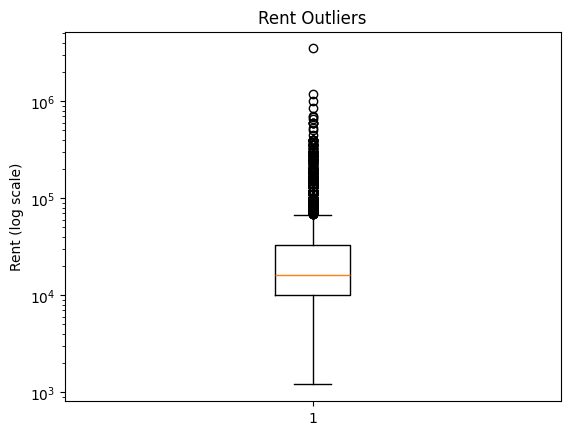

In [121]:
plt.boxplot(df['Rent'])
plt.yscale('log')
plt.ylabel('Rent (log scale)')
plt.title('Rent Outliers')
plt.show()

## Methods to Detect Outliers (IQR)

In [122]:
def remove_outliers_iqr(data, column_name='value'):
    q1 = data[column_name].quantile(0.25)
    q3 = data[column_name].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[column_name] >= lower) & (data[column_name] <= upper)]

cleaned_df = remove_outliers_iqr(df, column_name='Rent')
print(df.shape, cleaned_df.shape)

(4738, 17) (4220, 17)


## Methods to Detect Outliers (Z-score)

Z-score works best when data is approximately normally distributed. Rent is strongly right-skewed, so compare the result with IQR and model-based methods.

| Situation | Suggested Z-score threshold |
| --- | --- |
| Normal data with large sample size | **3.0** (classic standard) |
| Conservative threshold | 3.5 or 4.0 |
| Catch more outliers | 2.0 or 2.5 |
| High-risk context | Usually 2.5 |

In [123]:
from scipy.stats import zscore

def remove_outliers_zscore(data, column_name='Rent', threshold=3.0):
    scores = zscore(data[column_name])
    return data[np.abs(scores) < threshold]

df['zscore'] = zscore(df['Rent'])
cleaned_df = remove_outliers_zscore(df, column_name='Rent')
print(df.shape, cleaned_df.shape)

(4738, 18) (4672, 18)


## Methods to Detect Outliers (Isolation Forest)

In [124]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.15, random_state=42)
df['Rent_new'] = iso.fit_predict(df[['Rent']])
df_clean = df[df['Rent_new'] == 1].copy()
df_clean.drop(columns=['Rent_new'], inplace=True)
df.drop(columns=['Rent_new'], inplace=True)
df_clean.shape

(4039, 18)

## Methods to Detect Outliers (Local Outlier Factor (LOF))

In [125]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(contamination=0.15)
df['Rent_new'] = lof.fit_predict(df[['Rent']])
df_clean = df[df['Rent_new'] == 1].copy()
df_clean.drop(columns=['Rent_new'], inplace=True)
df.drop(columns=['Rent_new'], inplace=True)
df_clean.shape

(4180, 18)

## Methods to Detect Outliers (Elliptic Envelope)

In [126]:
from sklearn.covariance import EllipticEnvelope

ell = EllipticEnvelope(contamination=0.15, random_state=42)
df['Rent_new'] = ell.fit_predict(df[['Rent']])
df_clean = df[df['Rent_new'] == 1].copy()
df_clean.drop(columns=['Rent_new'], inplace=True)
df.drop(columns=['Rent_new'], inplace=True)
df_clean.shape

(4037, 18)

In [127]:
def estimate_contamination(data, column_name, factor=1.5):
    q1 = data[column_name].quantile(0.25)
    q3 = data[column_name].quantile(0.75)
    iqr = q3 - q1
    mask_outliers = (
        (data[column_name] < q1 - factor * iqr)
        | (data[column_name] > q3 + factor * iqr)
    )
    return mask_outliers.sum() / len(data)

In [128]:
contamination_value = estimate_contamination(df, 'Rent')
contamination_value

np.float64(0.10932883073026593)

### Remove Outliers (drop them)
Drops rows with Rent values outside the IQR boundaries.

In [129]:
def remove_outliers_drop(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[column] >= lower) & (data[column] <= upper)]

cleaned_df = remove_outliers_drop(df, 'Rent')
print(df.shape, cleaned_df.shape)

(4738, 18) (4220, 18)


### Cap (Winsorize)
Caps extreme values at the selected lower and upper percentiles.

In [130]:
from scipy.stats.mstats import winsorize

def cap_outliers(data, limits=(0.05, 0.05)):
    return winsorize(data, limits=limits)

cleaned_rent = cap_outliers(df['Rent'], (0.05, 0.05))
print(df.shape, cleaned_rent.shape)

(4738, 18) (4738,)


### Clip (Set min/max thresholds)
Restrict values to chosen Rent limits.

In [131]:
df['Rent'].max(), df['Rent'].min()

(np.float64(3500000.0), np.float64(1200.0))

In [132]:
def clip_data(data, min_value, max_value):
    return np.clip(data, min_value, max_value)

cleaned_rent = clip_data(df['Rent'], 1000, 300000)
print(df.shape, cleaned_rent.shape)

(4738, 18) (4738,)


In [133]:
X = df.drop(['Rent', 'zscore'], axis=1)
X.head()

,BHK,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new,Area Locality_freq
0,2,1100.000000,455,34980.56564,4,0.0,1,2.0,2,2022,5,0.0,0.0,1.0,34269.612957,2
1,2,967.924182,14,34980.56564,4,1.0,1,1.0,2,2022,5,0.0,0.0,1.0,34362.702434,2
2,2,1000.000000,14,34980.56564,4,1.0,1,1.0,2,2022,5,0.0,0.0,1.0,31324.414346,16
3,2,967.924182,10,34980.56564,4,0.0,1,1.0,2,2022,7,0.0,0.0,1.0,34475.739657,2
4,2,850.000000,10,34980.56564,4,0.0,0,1.0,2,2022,5,0.0,1.0,0.0,34379.255937,1


In [134]:
y = df['Rent']
y.head()

0    10000.0
1    20000.0
2    17000.0
3    10000.0
4     7500.0
Name: Rent, dtype: float64

# Spliting Data
### train test split

In [135]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (3790, 16)  y_train =  (3790,)
X_test  =  (948, 16)  y_test  =  (948,)


# Data Scaling (Normalization)

In [136]:
X_train.describe()

,BHK,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new,Area Locality_freq
count,3790.000000,3790.000000,3790.000000,3.790000e+03,3790.000000,3790.000000,3790.000000,3790.000000,3790.000000,3790.0,3790.000000,3790.000000,3790.000000,3790.000000,3790.000000,3790.000000
mean,2.074934,966.145810,230.293931,3.418082e+04,2.443008,0.758311,0.923483,1.959103,1.363325,2022.0,5.752770,0.000264,0.476253,0.523483,35663.917434,5.470712
std,0.833249,631.300586,163.495200,3.347367e+04,1.784008,0.687446,0.514198,0.886046,0.931644,0.0,0.833665,0.016244,0.499502,0.499514,13313.622548,6.040993
min,1.000000,10.000000,0.000000,1.021151e+04,0.000000,0.000000,0.000000,1.000000,0.000000,2022.0,4.000000,0.000000,0.000000,0.000000,20164.727066,1.000000
25%,2.000000,550.000000,26.000000,2.249028e+04,1.000000,0.000000,1.000000,1.000000,0.000000,2022.0,5.000000,0.000000,0.000000,0.000000,33909.165139,1.000000
50%,2.000000,850.000000,201.000000,3.498057e+04,2.000000,1.000000,1.000000,2.000000,2.000000,2022.0,6.000000,0.000000,0.000000,1.000000,34412.077844,3.000000
75%,3.000000,1200.000000,374.750000,3.498057e+04,4.000000,1.000000,1.000000,2.000000,2.000000,2022.0,6.000000,0.000000,1.000000,1.000000,34871.584533,8.000000
max,6.000000,7000.000000,479.000000,1.189294e+06,5.000000,2.000000,2.000000,7.000000,2.000000,2022.0,7.000000,1.000000,1.000000,1.000000,174270.362912,37.000000


## MinMaxScaler

In [137]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train[['BHK']] = my_scaler.fit_transform(X_train[['BHK']])
X_test[['BHK']] = my_scaler.transform(X_test[['BHK']])

In [138]:
X_train['BHK'].min(), X_train['BHK'].max()

(np.float64(0.0), np.float64(1.0000000000000002))

## StandardScaler

In [139]:
from sklearn.preprocessing import StandardScaler

my_scaler = StandardScaler()
X_train[['Size']] = my_scaler.fit_transform(X_train[['Size']])
X_test[['Size']] = my_scaler.transform(X_test[['Size']])

In [140]:
X_train['Size'].mean(), X_train['Size'].std()

(np.float64(-2.812174415937072e-17), np.float64(1.0001319522338659))

## RobustScaler
outliers

In [141]:
from sklearn.preprocessing import RobustScaler

my_scaler = RobustScaler()
X_train[['Bathroom']] = my_scaler.fit_transform(X_train[['Bathroom']])
X_test[['Bathroom']] = my_scaler.transform(X_test[['Bathroom']])

### Log1p
Rent is positive, so Log1p can reduce its right skew. These transformed targets are alternatives; y_train and y_test remain unchanged.

In [142]:
def log_transform(data):
    return np.log1p(data)

y_train_log = log_transform(y_train)
y_test_log = log_transform(y_test)
y_train_log.head()

4500    10.463132
3775     9.210440
266      8.612685
918     11.034906
3589     9.798183
Name: Rent, dtype: float64

### Box-Cox
Rent values are strictly positive. Fit the transformation on training Rent, then apply it to test Rent.

In [143]:
from sklearn.preprocessing import PowerTransformer

pt_boxcox = PowerTransformer(method='box-cox')
y_train_boxcox = pt_boxcox.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()
y_test_boxcox = pt_boxcox.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()
y_train_boxcox[:5]

array([ 0.78709469, -0.68028588, -1.64820968,  1.26760113,  0.08990349])

### Yeo-Johnson
Yeo-Johnson supports positive, zero, or negative targets; fit it on training Rent and reuse it on test Rent.

In [144]:
pt_yeojohnson = PowerTransformer(method='yeo-johnson')
y_train_yeojohnson = pt_yeojohnson.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()
y_test_yeojohnson = pt_yeojohnson.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()
y_train_yeojohnson[:5]

array([ 0.78711226, -0.68030106, -1.64821172,  1.26761765,  0.08990616])

In [145]:
X_train.head()

,BHK,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new,Area Locality_freq
4500,0.4,1.162602,196,115247.570705,3,1.0,0,1.0,2,2022,6,0.0,1.0,0.0,43236.475291,11
3775,0.2,-0.738487,198,19495.141410,1,1.0,1,-1.0,2,2022,5,0.0,0.0,1.0,34129.472329,4
266,0.0,-0.738487,455,13995.141410,4,0.0,1,-1.0,2,2022,5,0.0,1.0,0.0,33060.848907,7
918,0.4,0.212057,113,34980.565640,5,1.0,2,1.0,0,2022,7,0.0,1.0,0.0,35571.785203,1
3589,0.0,-0.706802,198,48396.113128,1,1.0,1,-1.0,2,2022,7,0.0,0.0,1.0,37271.578375,10


In [146]:
y_train.head()

4500    35000.0
3775    10000.0
266      5500.0
918     62000.0
3589    18000.0
Name: Rent, dtype: float64

In [147]:
X_test.head()

,BHK,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Posted Year,Posted Month,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Area Locality_new,Area Locality_freq
4455,0.2,0.132845,16,34980.565640,3,0.0,1,0.0,2,2022,6,0.0,0.0,1.0,34543.365469,1
1745,0.0,-0.976123,196,19826.855213,0,1.0,1,-1.0,2,2022,5,0.0,0.0,1.0,33271.943476,8
994,0.4,0.212057,158,129993.521880,5,1.0,1,0.0,0,2022,7,0.0,1.0,0.0,39546.283768,8
2178,0.2,-0.580063,196,34980.565640,0,1.0,1,0.0,2,2022,5,0.0,0.0,1.0,34265.310480,3
2608,0.6,2.746842,198,34980.565640,2,1.0,0,2.0,0,2022,7,0.0,1.0,0.0,35167.261490,2


In [148]:
y_test.head()

4455    15000.0
1745     8500.0
994     70000.0
2178     9500.0
2608    42000.0
Name: Rent, dtype: float64

In [149]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False
)

In [151]:
model.fit(X_train , y_train)

LinearRegression()

In [152]:
y_pred = model.predict(X_test)

In [153]:
y_pred[:5]

array([ 30819.94328596, -23101.68358844,  80797.13181944,   6640.99738744,
       142415.85811602])

In [155]:
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error


In [157]:
mae = mean_squared_error(y_test , y_pred)
mae

np.float64(1406282893.6568732)

In [158]:
mr2 = r2_score(y_test , y_pred)
mr2

0.46883200155908855